In [78]:
import thinkbayes
import numpy as np
import matplotlib.pyplot as plt

def MakePoissonPmf(lam, high):
    pmf = thinkbayes.Pmf()
    for k in np.arange(0, high+1):
        p = thinkbayes.EvalPoissonPmf(lam, k)
        pmf.Set(k,p)
    pmf.Normalize()
    return pmf

def MakeGoalPmf(suite):
    metapmf = thinkbayes.Pmf()
 
    for lam, prob in suite.Items():
        pmf = thinkbayes.MakePoissonPmf(lam, 10)
    metapmf.Set(pmf, prob)

    mix = MakeMixture(metapmf)
    return mix

def MakeMixture(metapmf, name='mix'):
    mix = thinkbayes.Pmf(name=name)
    for pmf, p1 in metapmf.Items():
        for x, p2 in pmf.Items():
            mix.Incr(x, p1 * p2)
    return mix

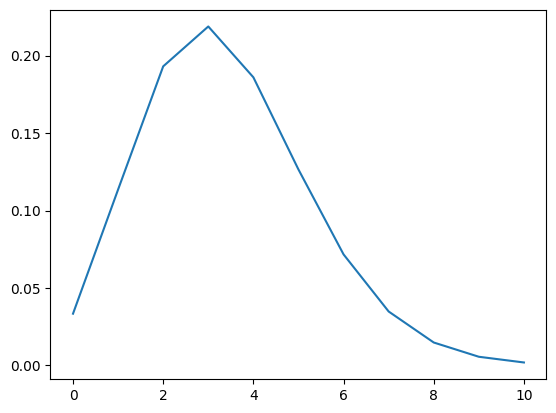

In [79]:
lam = 3.4
goal_dist = thinkbayes.MakePoissonPmf(lam, 10)

lam1, prob1 = zip(*goal_dist.Items())

plt.plot(lam1, prob1, label="")

In [83]:
USE_SUMMARY_DATA = True

class Hockey(thinkbayes.Suite):
    def __init__(self, name=''):
        if USE_SUMMARY_DATA:
            # prior based on each team's average goals scored
            mu = 2.8
            sigma = 0.3
        else:
            # prior based on each pair-wise match-up
            mu = 2.8
            sigma = 0.85

        pmf = thinkbayes.MakeGaussianPmf(mu, sigma, 4)
        thinkbayes.Suite.__init__(self, pmf, name=name)

    def Likelihood(self, data, hypo):
        lam = hypo
        k = data
        like = thinkbayes.EvalPoissonPmf(k, lam)
        return like

    
def MakeGoalPmf(suite, high=10):
    metapmf = thinkbayes.Pmf()

    for lam, prob in suite.Items():
        pmf = thinkbayes.MakePoissonPmf(lam, high)
        metapmf.Set(pmf, prob)
        
    mix = thinkbayes.MakeMixture(metapmf, name=suite.name)
    return mix

In [ ]:
suite1 = Hockey('bruins')
suite2 = Hockey('canucks')

suite1.UpdateSet([0,2,8,4])
suite2.UpdateSet([1,3,1,0])

goal_dist1 = MakeGoalPmf(suite1)
goal_dist2 = MakeGoalPmf(suite2)

lam1, prob1 = zip(*goal_dist1.Items())
lam2, prob2 = zip(*goal_dist2.Items())

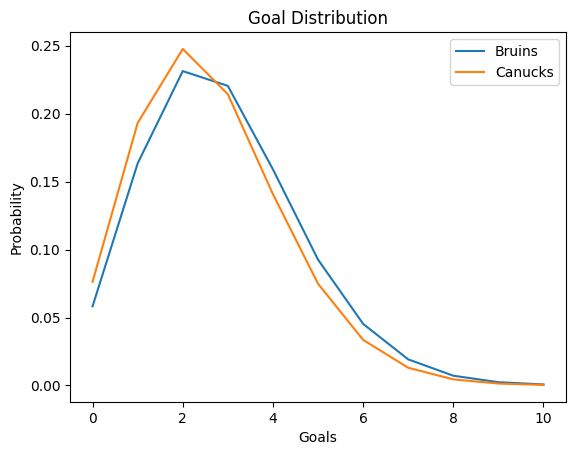

In [89]:
plt.plot(lam1, prob1, label="Bruins")
plt.plot(lam2, prob2, label="Canucks")
plt.xlabel("Goals")
plt.ylabel("Probability")
plt.title("Goal Distribution")
plt.legend()


========== suite ========== 
λ と P(λ | data)
λ = 2   確率 = 0.4
λ = 4   確率 = 0.6

========== metapmf ========== 
未来の得点分布 pmf と、その重み
P(X | λ=2)        重み = 0.4
P(X | λ=4)        重み = 0.6


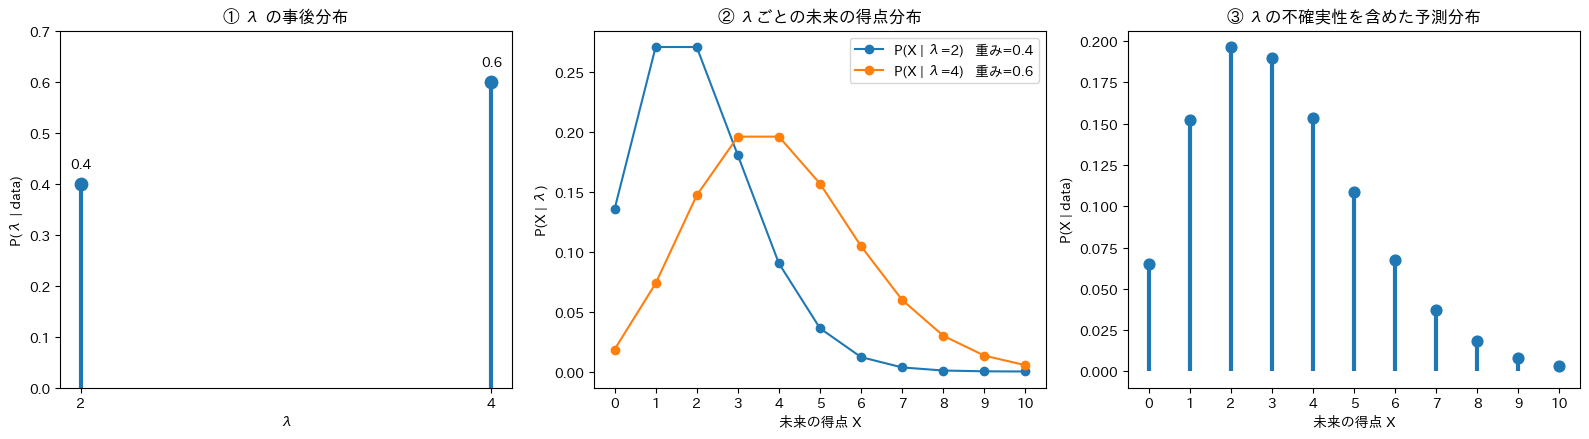

In [91]:
import thinkbayes
import matplotlib.pyplot as plt
import japanize_matplotlib


# ============================================================
# 1. λについての事後分布を作る
#
#    ここでは理解しやすくするため、
#    λ=2 の確率 0.4
#    λ=4 の確率 0.6
#    とする
#
#    これは P(λ | data)
# ============================================================

suite = thinkbayes.Pmf()

suite.Set(2, 0.4)
suite.Set(4, 0.6)


# ============================================================
# 2. λごとに「未来の得点分布」を作る
#
#    λ=2 なら P(X | λ=2)
#    λ=4 なら P(X | λ=4)
#
#    そして metapmf に
#
#        pmf → そのpmfの重み
#
#    として登録する
# ============================================================

metapmf = thinkbayes.Pmf()

for lam, prob in suite.Items():

    # λを固定したときの未来の得点分布
    pmf = thinkbayes.MakePoissonPmf(lam, 10)

    # グラフに表示するため名前を付ける
    pmf.name = f"P(X | λ={lam})"

    # ★ここが教科書のポイント
    #
    # pmf  = 「λを固定したときの未来の得点分布」
    # prob = 「そのλが正しいと思っている事後確率」
    #
    metapmf.Set(pmf, prob)


# ============================================================
# 3. metapmf の中身を確認
# ============================================================

print("========== suite ========== ")
print("λ と P(λ | data)")
for lam, prob in suite.Items():
    print(f"λ = {lam}   確率 = {prob}")


print()
print("========== metapmf ========== ")
print("未来の得点分布 pmf と、その重み")
for pmf, prob in metapmf.Items():
    print(f"{pmf.name:15s}   重み = {prob}")


# ============================================================
# 4. MakeMixture
#
#    λ=2 の予測分布 × 0.4
#    λ=4 の予測分布 × 0.6
#
#    を足し合わせる
# ============================================================

mix = thinkbayes.MakeMixture(metapmf)


# ============================================================
# 5. グラフ
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))


# ------------------------------------------------------------
# 左：P(λ | data)
# ------------------------------------------------------------

ax = axes[0]

lams = []
probs = []

for lam, prob in suite.Items():
    lams.append(lam)
    probs.append(prob)

ax.vlines(lams, 0, probs, linewidth=3)
ax.scatter(lams, probs, s=80)

ax.set_title("① λ の事後分布")
ax.set_xlabel("λ")
ax.set_ylabel("P(λ | data)")
ax.set_xticks(lams)
ax.set_ylim(0, 0.7)

for lam, prob in zip(lams, probs):
    ax.text(lam, prob + 0.03, f"{prob:.1f}",
            ha="center")


# ------------------------------------------------------------
# 中：P(X | λ)
#
# λ=2 と λ=4 それぞれについて
# 「未来の得点 X」がどう分布するか
# ------------------------------------------------------------

ax = axes[1]

for pmf, prob in metapmf.Items():

    xs = []
    ps = []

    for x, p in pmf.Items():
        xs.append(x)
        ps.append(p)

    ax.plot(
        xs,
        ps,
        marker="o",
        label=f"{pmf.name}   重み={prob}"
    )

ax.set_title("② λごとの未来の得点分布")
ax.set_xlabel("未来の得点 X")
ax.set_ylabel("P(X | λ)")
ax.set_xticks(range(0, 11))
ax.legend()


# ------------------------------------------------------------
# 右：混合した予測分布
#
# P(X | data)
#
# = Σ P(X | λ) P(λ | data)
# ------------------------------------------------------------

ax = axes[2]

xs = []
ps = []

for x, p in mix.Items():
    xs.append(x)
    ps.append(p)

ax.vlines(xs, 0, ps, linewidth=3)
ax.scatter(xs, ps, s=60)

ax.set_title("③ λの不確実性を含めた予測分布")
ax.set_xlabel("未来の得点 X")
ax.set_ylabel("P(X | data)")
ax.set_xticks(range(0, 11))

plt.tight_layout()
plt.show()